# NSGA-II itinerary optimization — evaluation
This notebook visualizes outputs produced by the local FastAPI NSGA-II evaluation. It **does not train** NSGA-II or claim global optimality. Upload `summary.csv` and `routes.csv` from `evaluation_results` to Colab session storage.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
summary = pd.read_csv("/content/summary.csv")
routes = pd.read_csv("/content/routes.csv")
print("Scenarios:", len(summary), "Displayed routes:", len(routes))
display(summary)
display(routes.head())

Scenarios: 4 Displayed routes: 12


,scenario,status,runtime_seconds,returned_options,distinct_displayed_routes,candidate_pareto_routes_reported,error
0,kandy_nature,PASS,4.227,3,3,56,NaN
1,sigiriya_history,PASS,3.819,3,3,85,NaN
2,kandy_culture,PASS,3.996,3,3,29,NaN
3,low_budget,PASS,3.760,3,3,22,NaN


,scenario,option,stops,cost_usd,straight_line_km,time_proxy_hours,preference_match_percent,sightseeing_value,passed_constraints,destination_ids
0,kandy_nature,cheapest,6,0.0,94.85,9.37,58.3,8.50,True,23-42-41-40-10-39
1,kandy_nature,shortest_straight_line,2,10.0,1.00,2.53,75.0,3.50,True,23-3
2,kandy_nature,best_preference_match,3,12.0,27.78,6.69,100.0,6.75,True,4-23-76
3,sigiriya_history,cheapest,5,0.0,159.04,9.48,60.0,7.25,True,64-57-59-61-58
4,sigiriya_history,shortest_straight_line,2,33.0,1.06,6.03,75.0,3.50,True,1-2


In [3]:
assert not summary.empty and not routes.empty
assert (summary["status"] == "PASS").all(), "One or more scenarios failed"
assert routes["passed_constraints"].astype(str).str.lower().eq("true").all(), "Constraint violation found"
print("Recorded scenario and route checks passed")

Recorded scenario and route checks passed


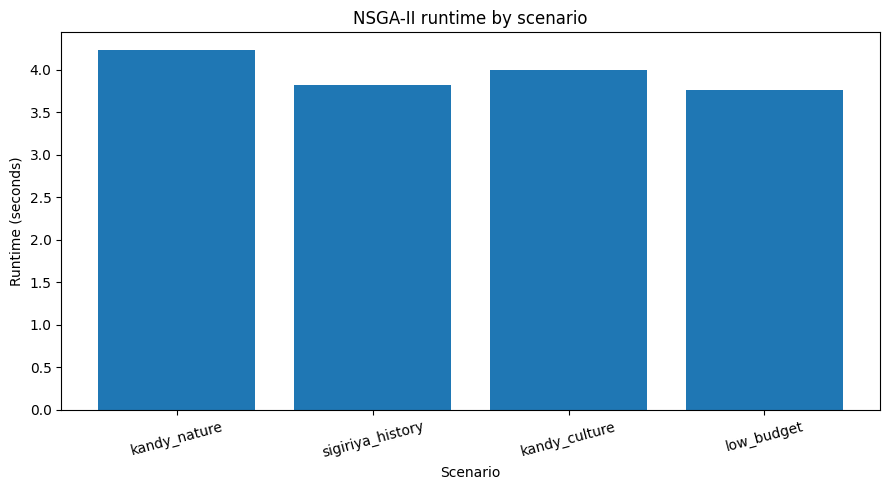

In [4]:
plt.figure(figsize=(9,5))
plt.bar(summary["scenario"], summary["runtime_seconds"])
plt.xticks(rotation=15)
plt.xlabel("Scenario")
plt.ylabel("Runtime (seconds)")
plt.title("NSGA-II runtime by scenario")
plt.tight_layout()
plt.savefig("runtime_by_scenario.png", dpi=160)
plt.show()

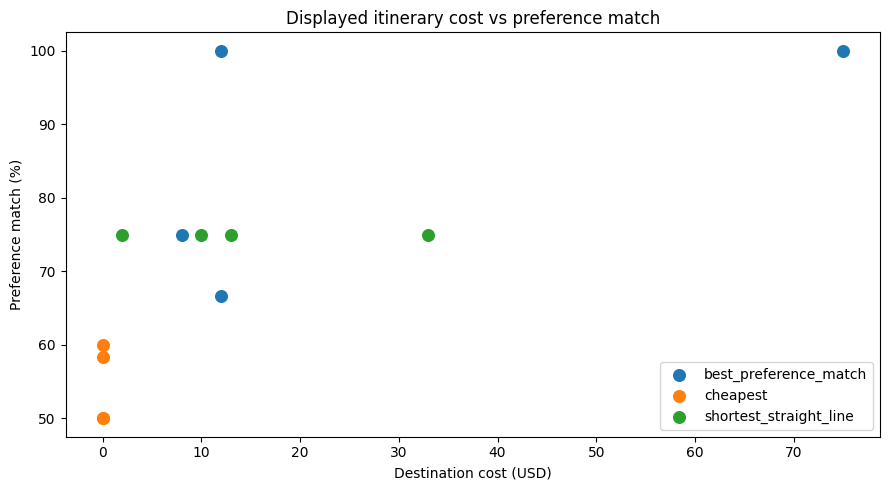

In [5]:
plt.figure(figsize=(9,5))
for option, group in routes.groupby("option"):
    plt.scatter(group["cost_usd"], group["preference_match_percent"], label=option, s=70)
plt.xlabel("Destination cost (USD)")
plt.ylabel("Preference match (%)")
plt.title("Displayed itinerary cost vs preference match")
plt.legend()
plt.tight_layout()
plt.savefig("cost_vs_preference.png", dpi=160)
plt.show()

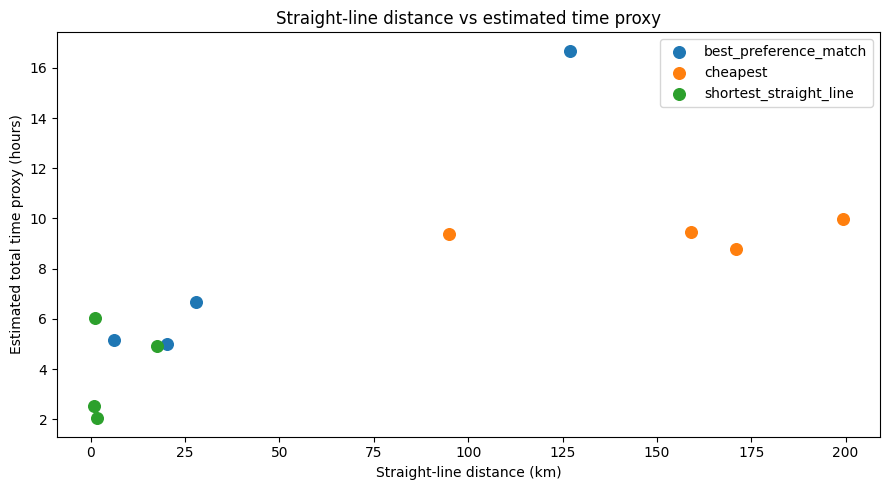

In [6]:
plt.figure(figsize=(9,5))
for option, group in routes.groupby("option"):
    plt.scatter(group["straight_line_km"], group["time_proxy_hours"], label=option, s=70)
plt.xlabel("Straight-line distance (km)")
plt.ylabel("Estimated total time proxy (hours)")
plt.title("Straight-line distance vs estimated time proxy")
plt.legend()
plt.tight_layout()
plt.savefig("distance_vs_time.png", dpi=160)
plt.show()

In [7]:

import pandas as pd

routes = pd.read_csv("routes.csv")

passed = routes["passed_constraints"].astype(str).str.lower().eq("true")

rate = passed.mean() * 100

print("NSGA-II Constraint Satisfaction Rate:", round(rate, 2), "%")
print("Routes evaluated:", len(routes))


NSGA-II Constraint Satisfaction Rate: 100.0 %
Routes evaluated: 12


## Research limitations
- Results reflect four scenarios and the three displayed itineraries per scenario.
- Straight-line distances and a 40 km/h assumption are **not road-network routes or measured travel times**.
- Destination fees exclude transport, food, and lodging.
- A single random seed and no baseline comparison do not demonstrate algorithm superiority.
- Hazard avoidance is a separate destination-proximity screening prototype.